# Notebook 01: Data Exploration and Statistics

The purpose of this notebook is to explore the Amazon Reviews 2023 Electronics Reviews dataset before any preprocessing is performed.

The exploration aims to:

- understand the structure of the review data
- identify missing values
- analyse users and products
- inspect timestamps
- determine appropriate preprocessing decisions

## 1. Imports

In [21]:
import gzip
import json
import pickle
import time

from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime, timezone


## 2. Paths

In [2]:

PROJECT_ROOT = Path("..")

RAW_DATA = PROJECT_ROOT / "data" / "raw"

REVIEWS_FILE = RAW_DATA / "Electronics.jsonl.gz"
METADATA_FILE = RAW_DATA / "meta_Electronics.jsonl.gz"

In [3]:
print("Reviews file exists:", REVIEWS_FILE.exists())
print("Metadata file exists:", METADATA_FILE.exists())

Reviews file exists: True
Metadata file exists: True


## 3. Read the first five review records

In [4]:
sample_reviews = []

with gzip.open(REVIEWS_FILE, "rt", encoding="utf-8") as f:
    for i, line in enumerate(f):
        sample_reviews.append(json.loads(line))
        if i == 4:
            break

## 4. What fields does one review contain?

In [5]:
print("Available review fields:\n")

for field in sample_reviews[0].keys():
    print(field)

Available review fields:

rating
title
text
images
asin
parent_asin
user_id
timestamp
helpful_vote
verified_purchase


In [6]:
sample_reviews[0]

{'rating': 3.0,
 'title': 'Smells like gasoline! Going back!',
 'text': 'First & most offensive: they reek of gasoline so if you are sensitive/allergic to petroleum products like I am you will want to pass on these.  Second: the phone adapter is useless as-is. Mine was not drilled far enough to be able to tighten it into place for my iPhone 12 max. It just slipped & slid all over. Stupid me putting the adapter together first without picking up the binoculars to smell them bc I wasted 15 minutes trying to figure out how to put the adapter together bc it does not come with instructions!  I had to come back here to the website which was a total pain. Third: the tripod is also useless. I would not trust the iOS to hold my $1600 phone nor even a Mattel Barbie for that matter. It’s just inefficient for the job imo.  Third: in order to try to give an honest review I did don gloves & eyewear to check the binoculars out.  They seemed average except for mine seemed to be missing about 10% of the

## 5. Check Data Types

Field types matter for later processing. Timestamps are stored as integer milliseconds
rather than dates, and ratings as floats, both of which affect how the interactions are
sorted and filtered in Notebook 03.

In [7]:
for field, value in sample_reviews[0].items():
    print(f"{field:<20} {type(value).__name__}")

rating               float
title                str
text                 str
images               list
asin                 str
parent_asin          str
user_id              str
timestamp            int
helpful_vote         int
verified_purchase    bool


## 6. Compare `asin` and `parent_asin`

The Amazon Reviews dataset provides both `asin` and `parent_asin` as product identifiers. This section investigates whether these attributes can be used interchangeably or whether they represent different entities. Understanding this distinction is important before selecting the product identifier used to construct the user–item interaction graph.

In [8]:
sample = []

with gzip.open(REVIEWS_FILE, "rt", encoding="utf-8") as file:
    for i, line in enumerate(file):
        sample.append(json.loads(line))

        if i >= 499:
            break

different = sum(
    review["asin"] != review["parent_asin"]
    for review in sample
)

print(f"Different ASINs: {different} out of {len(sample)} reviews")

Different ASINs: 225 out of 500 reviews


# 7. Dataset Overview and Analysis

The Electronics review dataset is approximately 6 GB in compressed JSONL format. Loading the entire dataset into memory is inefficient and exceeds practical memory limits. Therefore, the dataset is processed sequentially in a single pass. During this scan, summary statistics are collected without storing all reviews simultaneously, making the analysis scalable while preserving the required information for subsequent preprocessing.

In [9]:
CACHE_FILE = PROJECT_ROOT / "data" / "processed" / "dataset_statistics.pkl"

CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)

### Automatic load or scan

The full scan takes a long time over 6 GB, so the summary statistics are cached to disk
on the first run and read back afterwards.

In [10]:
FIELDS = [
    "rating",
    "title",
    "text",
    "images",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "helpful_vote",
    "verified_purchase",
]


if CACHE_FILE.exists():
    print("Cached statistics found. Loading...")

    with open(CACHE_FILE, "rb") as file:
        statistics = pickle.load(file)

    total_reviews = statistics["total_reviews"]
    rating_counts = statistics["rating_counts"]
    missing_counts = statistics["missing_counts"]
    user_activity = statistics["user_activity"]
    product_activity = statistics["product_activity"]
    earliest_timestamp = statistics["earliest_timestamp"]
    latest_timestamp = statistics["latest_timestamp"]

    print("Statistics loaded successfully.")

else:
    print("No cached statistics found.")
    print("Scanning the full dataset...")

    total_reviews = 0

    rating_counts = Counter()
    missing_counts = Counter()

    user_activity = Counter()
    product_activity = Counter()

    earliest_timestamp = None
    latest_timestamp = None

    start_time = time.time()

    with gzip.open(REVIEWS_FILE, "rt", encoding="utf-8") as file:
        for line in file:
            review = json.loads(line)
            total_reviews += 1

            # Rating distribution
            rating = review.get("rating")

            if rating is not None:
                rating_counts[rating] += 1

            # Missing-value counts
            for field in FIELDS:
                value = review.get(field)

                if value is None or value == "" or value == []:
                    missing_counts[field] += 1

            # User activity
            user_id = review.get("user_id")

            if user_id:
                user_activity[user_id] += 1

            # Product activity
            parent_asin = review.get("parent_asin")

            if parent_asin:
                product_activity[parent_asin] += 1

            # Timestamp range
            timestamp = review.get("timestamp")

            if timestamp is not None:
                if earliest_timestamp is None or timestamp < earliest_timestamp:
                    earliest_timestamp = timestamp

                if latest_timestamp is None or timestamp > latest_timestamp:
                    latest_timestamp = timestamp

            # Progress update
            if total_reviews % 500_000 == 0:
                elapsed = time.time() - start_time
                speed = total_reviews / elapsed

                print(
                    f"Processed {total_reviews:,} reviews "
                    f"| {speed:,.0f} reviews/second "
                    f"| {elapsed / 60:.1f} minutes"
                )

    elapsed = time.time() - start_time

    statistics = {
        "total_reviews": total_reviews,
        "rating_counts": rating_counts,
        "missing_counts": missing_counts,
        "user_activity": user_activity,
        "product_activity": product_activity,
        "earliest_timestamp": earliest_timestamp,
        "latest_timestamp": latest_timestamp,
    }

    with open(CACHE_FILE, "wb") as file:
        pickle.dump(statistics, file, protocol=pickle.HIGHEST_PROTOCOL)

    print("\nDataset scan completed.")
    print(f"Elapsed time: {elapsed / 60:.2f} minutes")
    print(f"Statistics saved to: {CACHE_FILE}")

Cached statistics found. Loading...
Statistics loaded successfully.


## 7.1 Dataset Summary

In [22]:
def as_date(ms):
    return datetime.fromtimestamp(ms / 1000, tz=timezone.utc).strftime("%d %B %Y")


span_years = (latest_timestamp - earliest_timestamp) / (1000 * 60 * 60 * 24 * 365.25)

print(f"Total reviews:   {total_reviews:,}")
print(f"Unique users:    {len(user_activity):,}")
print(f"Unique products: {len(product_activity):,}")
print(f"Earliest review: {as_date(earliest_timestamp)}  ({earliest_timestamp})")
print(f"Latest review:   {as_date(latest_timestamp)}  ({latest_timestamp})")
print(f"Span:            {span_years:.1f} years")

Total reviews:   43,886,944
Unique users:    18,286,191
Unique products: 1,609,860
Earliest review: 18 November 1996  (848336280000)
Latest review:   13 September 2023  (1694625981867)
Span:            26.8 years


In [12]:
rating_counts_series = pd.Series(
    rating_counts,
    name="review_count",
).sort_index()

missing_counts_series = pd.Series(
    missing_counts,
    name="missing_count",
).reindex(FIELDS, fill_value=0)

user_activity_series = pd.Series(
    user_activity,
    name="review_count",
)

product_activity_series = pd.Series(
    product_activity,
    name="review_count",
)

## 7.2 Rating Distribution

The rating distribution informs whether to treat only high ratings as positive feedback.
The dataset is heavily skewed towards 5-star reviews, which is typical of e-commerce data
and means a threshold would discard a large share of the interactions. Notebook 03
follows the official benchmark pipeline and applies no rating threshold, treating every
review as an implicit positive.

0.0           2
1.0     5358800
2.0     2257604
3.0     2883065
4.0     5557725
5.0    27829748
Name: review_count, dtype: int64

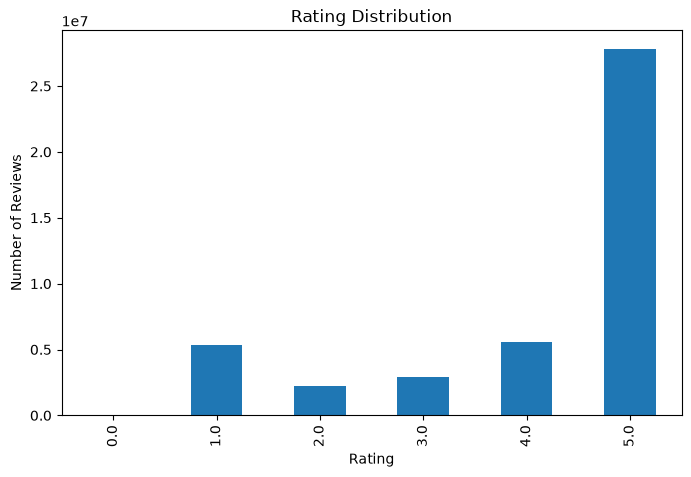

In [13]:
display(rating_counts_series)

rating_counts_series.plot(
    kind="bar",
    figsize=(8,5),
    title="Rating Distribution"
)
plt.xlabel("Rating")

plt.ylabel("Number of Reviews")

plt.show()

## 7.3 Missing Values

Determine which fields can be relied on downstream.

In [14]:

display(missing_counts_series.sort_values(ascending=False))

images               41863199
text                     2534
title                       1
rating                      0
asin                        0
parent_asin                 0
user_id                     0
timestamp                   0
helpful_vote                0
verified_purchase           0
Name: missing_count, dtype: int64

In [15]:
missing_percentage = (missing_counts_series / total_reviews * 100).round(2)

display(
    pd.DataFrame({
        "Missing Count": missing_counts_series,
        "Missing (%)": missing_percentage
    }).sort_values("Missing Count", ascending=False)
)

,Missing Count,Missing (%)
images,41863199,95.39
text,2534,0.01
title,1,0.00
rating,0,0.00
asin,0,0.00
parent_asin,0,0.00
user_id,0,0.00
timestamp,0,0.00
helpful_vote,0,0.00
verified_purchase,0,0.00


## 7.4 User Activity

How many reviews each user writes determines how much collaborative signal is available
per user, and this is the statistic that most shapes the rest of the project. The
distribution is extremely skewed: the great majority of users appear only once or twice,
which motivates the 5-core filtering applied in Notebook 03 and explains why the filtered
dataset remains sparse afterwards.

In [16]:
display(user_activity_series.describe())

count    1.828619e+07
mean     2.400005e+00
std      3.924697e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      1.034000e+03
Name: review_count, dtype: float64

## 7.5 Product Popularity

Product popularity follows the same long-tailed pattern as user activity. A small number
of products account for a large share of the reviews while most are reviewed only a few
times, which is what makes popularity a surprisingly strong baseline and what makes rare
items hard to recommend.

In [17]:

display(product_activity_series.describe())

count    1.609860e+06
mean     2.726134e+01
std      3.590900e+02
min      1.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      1.782390e+05
Name: review_count, dtype: float64

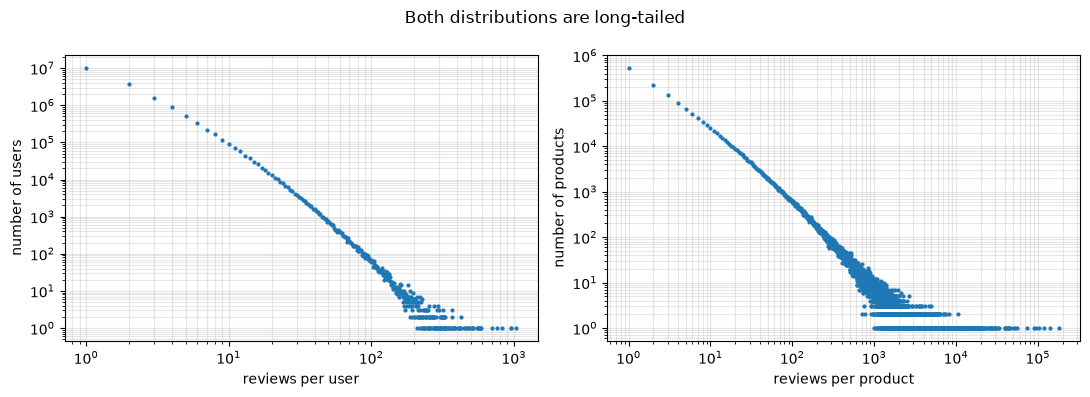

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, series, label in [
    (axes[0], user_activity_series, "reviews per user"),
    (axes[1], product_activity_series, "reviews per product"),
]:
    counts = series.value_counts().sort_index()
    ax.loglog(counts.index, counts.values, marker=".", linestyle="none", markersize=4)
    ax.set(xlabel=label, ylabel="number of users" if "user" in label else "number of products")
    ax.grid(alpha=0.3, which="both")

fig.suptitle("Both distributions are long-tailed")
fig.tight_layout()
plt.show()

FIGURES_DIR=PROJECT_ROOT / "figures"
fig.savefig(FIGURES_DIR / "01_long_tail.png", dpi=200)

# Findings

The dataset is very large, but most users have very little history. Half of the users
wrote only one review and three quarters wrote no more than two. This leaves very little
collaborative information for most users and motivates the 5-core filtering in Notebook
03.

The same pattern appears for products. Half have three reviews or fewer, while the most
reviewed product has 178,239. This suggests popularity could be a strong baseline and
that less popular items may be much harder to recommend.

Ratings are mostly positive: 63% are five stars and 76% are four stars or above. Using
only high ratings as positive interactions would therefore remove around a quarter of
the data. The official benchmark does not apply a rating threshold, so Notebook 03
follows the same approach.

Missing values are not a major issue for the interaction data. `images` is the only
field with substantial missingness (95%), while the fields needed to build the
interaction graph are complete.

The reviews cover a long period, from November 1996 to September 2023. This gives enough
temporal coverage to use the global timestamp split introduced in Notebook 04.